In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid", palette="deep")

df = pd.read_csv('data/processed/supermarket_sales_clean.csv')
df['Date'] = pd.to_datetime(df['Date'])

os.makedirs('outputs', exist_ok=True)

print("Dataset siap divisualisasikan:", df.shape)

Dataset siap divisualisasikan: (1000, 22)


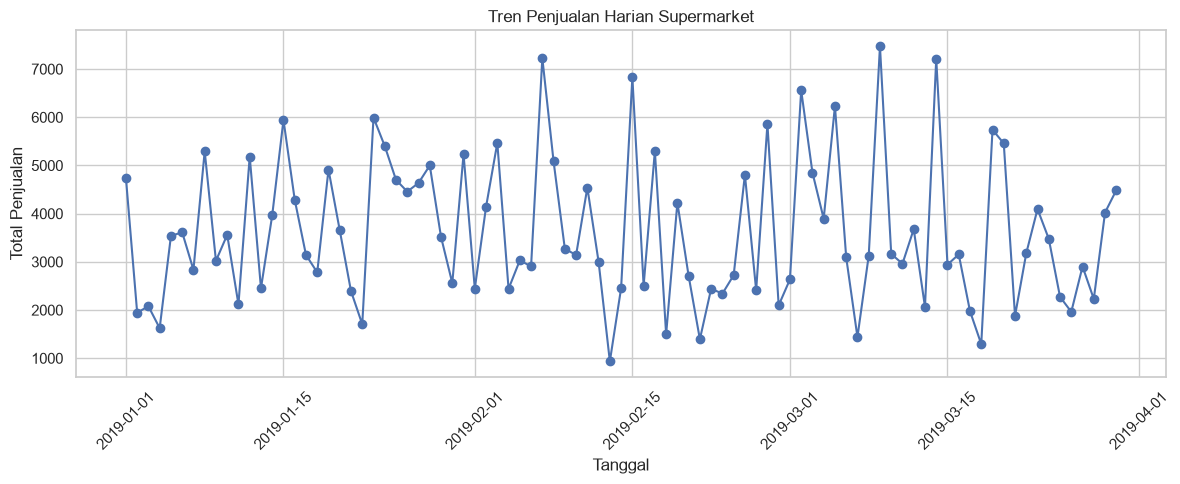

In [2]:
daily_sales = df.groupby('Date')['Total'].sum()

plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values, marker='o',
         linewidth=1.5)

plt.title('Tren Penjualan Harian Supermarket')
plt.xlabel('Tanggal')
plt.ylabel('Total Penjualan')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('outputs/01_tren_penjualan_harian.png', dpi=300)
plt.show()

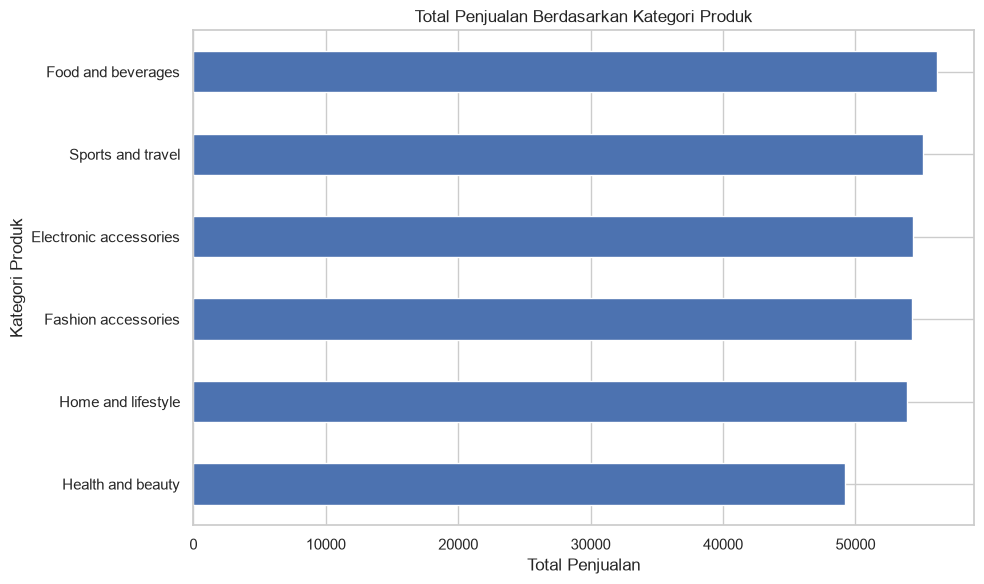

In [3]:
product_sales = df.groupby('Product line')['Total'].sum().sort_values()

plt.figure(figsize=(10, 6))
product_sales.plot(kind='barh')

plt.title('Total Penjualan Berdasarkan Kategori Produk')
plt.xlabel('Total Penjualan')
plt.ylabel('Kategori Produk')
plt.tight_layout()

plt.savefig('outputs/02_penjualan_kategori.png', dpi=300)
plt.show()

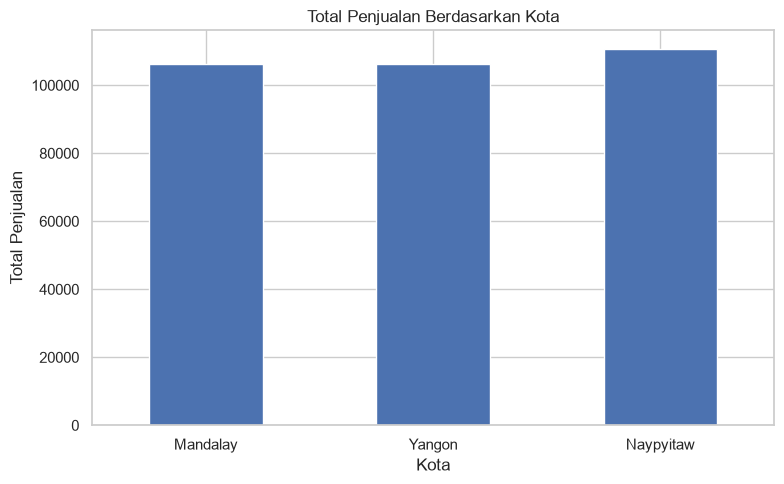

In [4]:
branch_sales = df.groupby('City')['Total'].sum().sort_values()

plt.figure(figsize=(8, 5))
branch_sales.plot(kind='bar')

plt.title('Total Penjualan Berdasarkan Kota')
plt.xlabel('Kota')
plt.ylabel('Total Penjualan')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('outputs/03_penjualan_cabang.png', dpi=300)
plt.show()

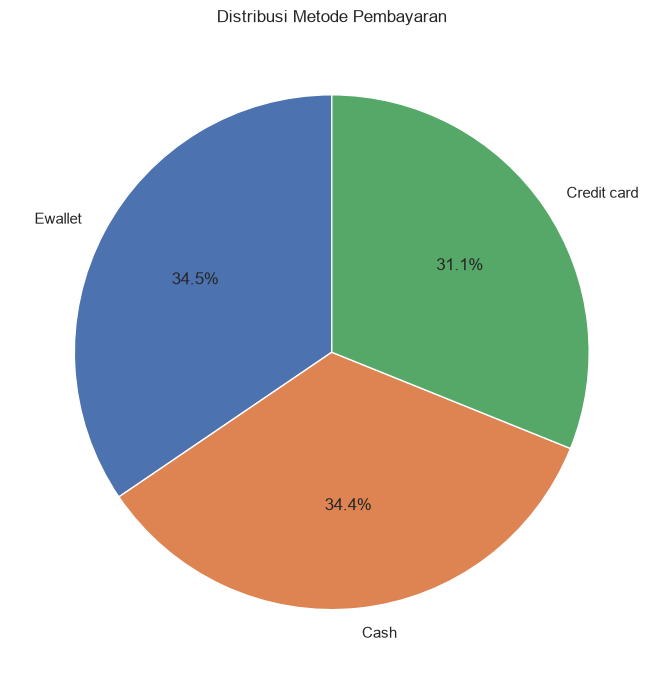

In [5]:
payment_counts = df['Payment'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribusi Metode Pembayaran')
plt.tight_layout()

plt.savefig('outputs/04_metode_pembayaran.png', dpi=300)
plt.show()

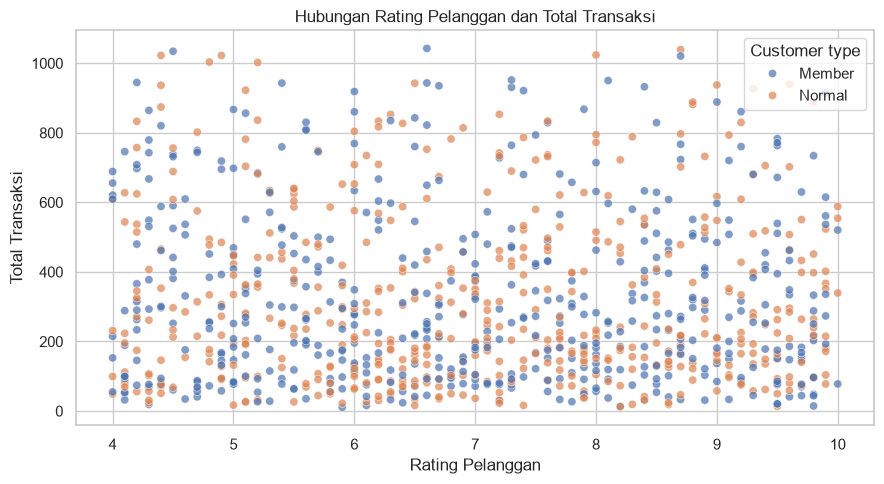

In [6]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Rating',
    y='Total',
    hue='Customer type',
    alpha=0.7
)

plt.title('Hubungan Rating Pelanggan dan Total Transaksi')
plt.xlabel('Rating Pelanggan')
plt.ylabel('Total Transaksi')
plt.tight_layout()

plt.savefig('outputs/05_rating_vs_transaksi.png', dpi=300)
plt.show()

In [7]:
df.groupby('Product line')['Total'].sum().to_csv(
    'outputs/ringkasan_produk.csv'
)

df.groupby('City')['Total'].sum().to_csv(
    'outputs/ringkasan_cabang.csv'
)

df.groupby('Payment')['Total'].sum().to_csv(
    'outputs/ringkasan_pembayaran.csv'
)

df.groupby('Month Name')['Total'].sum().to_csv(
    'outputs/ringkasan_bulanan.csv'
)

print("Seluruh ringkasan berhasil disimpan.")

Seluruh ringkasan berhasil disimpan.
